Paquetes necesarios

In [2]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



Relación mm/píxel: 0.12283188754211355
Diámetro 16.29 mm -> 0.01E
Diámetro 22.32 mm -> 0.20E
Diámetro 18.82 mm -> 0.02E
Diámetro 24.24 mm -> 0.50E
Diámetro 19.72 mm -> 0.10E
Diámetro 23.25 mm -> 1.00E
Diámetro 21.23 mm -> 0.05E
Diámetro 25.88 mm -> 2.00E
Total: 3.88 Euros


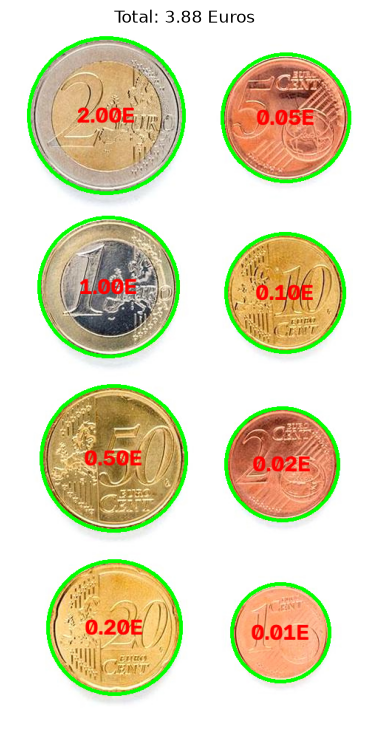

In [3]:
# Diccionario de monedas (diámetro en mm : valor en euros)
monedas_ref = {16.25: 0.01, 18.75: 0.02, 21.25: 0.05, 19.75: 0.10,
               22.25: 0.20, 24.25: 0.50, 23.25: 1.00, 25.75: 2.00}
tolerancia = 0.6 # mm de margen de error

# Guarda el punto donde se hace clic con el ratón
clic = []
def raton(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        clic.append((x, y))

#Carga imagen con monedas
img = cv2.imread('Monedas.jpg')

#Convierte a gris, suaviza y umbraliza con Otsu (invertido, monedas en blanco)
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gris = cv2.GaussianBlur(gris, (5, 5), 0)
th, img_th = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

#Obtiene únicamente los contornos externos
contornos, hierarchy = cv2.findContours(img_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#Muestra la imagen y espera a que se haga clic en la moneda de 1 euro
cv2.namedWindow('Clic en la moneda de 1 euro')
cv2.setMouseCallback('Clic en la moneda de 1 euro', raton)
while len(clic) == 0:
    cv2.imshow('Clic en la moneda de 1 euro', img)
    if cv2.waitKey(20) == 27:
        break
cv2.destroyAllWindows()

#Busca el contorno que contiene el clic -> moneda de 1 euro -> relación mm/píxel
for c in contornos:
    if cv2.pointPolygonTest(c, (float(clic[0][0]), float(clic[0][1])), False) >= 0:
        (cx, cy), radio = cv2.minEnclosingCircle(c)
        ratio_mm_pix = 23.25 / (2 * radio)
print('Relación mm/píxel:', ratio_mm_pix)

#Recorre los contornos, identifica cada moneda y suma su valor
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
dinero_total = 0.0
for c in contornos:
    #Área del contorno
    area = cv2.contourArea(c)
    #Área mínima
    if area < 500:
        continue
    #Mínimo círculo que contiene al contorno
    (cx, cy), radio = cv2.minEnclosingCircle(c)

    #Si el área no se parece a la del círculo, no es una moneda
    if area / (np.pi * radio ** 2) < 0.8:
        cv2.drawContours(img_rgb, [c], -1, (255, 0, 0), 3)
        continue

    #Diámetro en mm y moneda con el diámetro más cercano
    diametro_mm = 2 * radio * ratio_mm_pix
    d_ref = min(monedas_ref, key=lambda d: abs(d - diametro_mm))
    if abs(d_ref - diametro_mm) <= tolerancia:
        valor = monedas_ref[d_ref]
        dinero_total += valor
        texto = f"{valor:.2f}E"
    else:
        texto = "?"
    print(f"Diámetro {diametro_mm:.2f} mm -> {texto}")

    cv2.circle(img_rgb, (int(cx), int(cy)), int(radio), (0, 255, 0), 3)
    cv2.putText(img_rgb, texto, (int(cx) - 40, int(cy) + 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 3)

print(f"Total: {dinero_total:.2f} Euros")

plt.figure(figsize=(5, 9))
plt.axis("off")
plt.title(f"Total: {dinero_total:.2f} Euros")
plt.imshow(img_rgb)
plt.show()

Relación mm/píxel: 0.19891936603224983
Diámetro 23.20 mm -> 1.00E
Diámetro 23.25 mm -> 1.00E
Diámetro 25.55 mm -> 2.00E
Diámetro 25.84 mm -> 2.00E
Diámetro 24.04 mm -> 0.50E
Diámetro 24.09 mm -> 0.50E
Diámetro 21.20 mm -> 0.05E
Diámetro 21.30 mm -> 0.05E
Diámetro 22.29 mm -> 0.20E
Diámetro 22.17 mm -> 0.20E
Diámetro 18.76 mm -> 0.02E
Diámetro 18.83 mm -> 0.02E
Diámetro 19.37 mm -> 0.10E
Diámetro 16.17 mm -> 0.01E
Diámetro 16.19 mm -> 0.01E
Diámetro 19.66 mm -> 0.10E
Total: 7.76 Euros


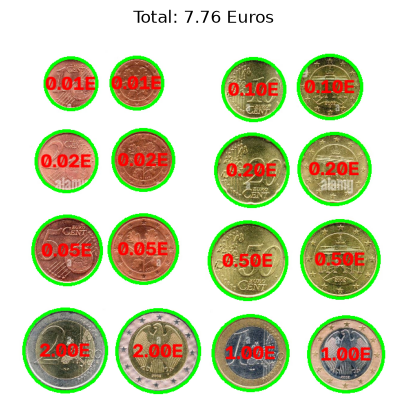

In [4]:
# Diccionario de monedas (diámetro en mm : valor en euros)
monedas_ref = {16.25: 0.01, 18.75: 0.02, 21.25: 0.05, 19.75: 0.10,
               22.25: 0.20, 24.25: 0.50, 23.25: 1.00, 25.75: 2.00}
tolerancia = 0.6 # mm de margen de error

# Guarda el punto donde se hace clic con el ratón
clic = []
def raton(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        clic.append((x, y))

#Carga imagen con monedas
img = cv2.imread('Monedas1.jpg')
#Reduce imágenes grandes para que se vean completas en la ventana (lado mayor máx. 600 px)
escala = 600 / max(img.shape[0], img.shape[1])
if escala < 1:
    img = cv2.resize(img, None, fx=escala, fy=escala)

#Convierte a gris, suaviza y umbraliza con Otsu (invertido, monedas en blanco)
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gris = cv2.GaussianBlur(gris, (5, 5), 0)
th, img_th = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

#Obtiene únicamente los contornos externos
contornos, hierarchy = cv2.findContours(img_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#Muestra la imagen y espera a que se haga clic en la moneda de 1 euro
cv2.namedWindow('Clic en la moneda de 1 euro')
cv2.setMouseCallback('Clic en la moneda de 1 euro', raton)
while len(clic) == 0:
    cv2.imshow('Clic en la moneda de 1 euro', img)
    if cv2.waitKey(20) == 27:
        break
cv2.destroyAllWindows()

#Busca el contorno que contiene el clic -> moneda de 1 euro -> relación mm/píxel
for c in contornos:
    if cv2.pointPolygonTest(c, (float(clic[0][0]), float(clic[0][1])), False) >= 0:
        (cx, cy), radio = cv2.minEnclosingCircle(c)
        ratio_mm_pix = 23.25 / (2 * radio)
print('Relación mm/píxel:', ratio_mm_pix)

#Recorre los contornos, identifica cada moneda y suma su valor
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
dinero_total = 0.0
for c in contornos:
    #Área del contorno
    area = cv2.contourArea(c)
    #Área mínima
    if area < 500:
        continue
    #Mínimo círculo que contiene al contorno
    (cx, cy), radio = cv2.minEnclosingCircle(c)

    #Si el área no se parece a la del círculo, no es una moneda
    if area / (np.pi * radio ** 2) < 0.8:
        cv2.drawContours(img_rgb, [c], -1, (255, 0, 0), 3)
        continue

    #Diámetro en mm y moneda con el diámetro más cercano
    diametro_mm = 2 * radio * ratio_mm_pix
    d_ref = min(monedas_ref, key=lambda d: abs(d - diametro_mm))
    if abs(d_ref - diametro_mm) <= tolerancia:
        valor = monedas_ref[d_ref]
        dinero_total += valor
        texto = f"{valor:.2f}E"
    else:
        texto = "?"
    print(f"Diámetro {diametro_mm:.2f} mm -> {texto}")

    cv2.circle(img_rgb, (int(cx), int(cy)), int(radio), (0, 255, 0), 3)
    cv2.putText(img_rgb, texto, (int(cx) - 40, int(cy) + 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 3)

print(f"Total: {dinero_total:.2f} Euros")

plt.figure(figsize=(5, 9))
plt.axis("off")
plt.title(f"Total: {dinero_total:.2f} Euros")
plt.imshow(img_rgb)
plt.show()

In [5]:
clic = []
ratio_mm_pix = None

vid = cv2.VideoCapture(1)
cv2.namedWindow('Demostrador Monedas')
cv2.setMouseCallback('Demostrador Monedas', raton)

while True:
    ret, frame = vid.read()
    if not ret:
        break

    #Gris, suavizado, umbralizado de Otsu y contornos externos
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    th, img_th = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contornos, hierarchy = cv2.findContours(img_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    #Calibración: el contorno donde se hace clic es la moneda de 1 euro
    if len(clic) > 0:
        x_clic, y_clic = clic.pop()
        for c in contornos:
            if cv2.pointPolygonTest(c, (float(x_clic), float(y_clic)), False) >= 0:
                (cx, cy), radio = cv2.minEnclosingCircle(c)
                ratio_mm_pix = 23.25 / (2 * radio)

    dinero_total = 0.0
    for c in contornos:
        area = cv2.contourArea(c)
        if area < 500:
            continue
        (cx, cy), radio = cv2.minEnclosingCircle(c)
        x, y, r = int(cx), int(cy), int(radio)

        #Objetos no circulares: no son monedas
        if area / (np.pi * radio ** 2) < 0.8:
            cv2.drawContours(frame, [c], -1, (255, 0, 0), 2)
            continue

        cv2.circle(frame, (x, y), r, (0, 255, 0), 2)

        #Clasificar moneda buscando el diámetro más cercano
        if ratio_mm_pix is not None:
            diametro_mm = 2 * radio * ratio_mm_pix
            d_ref = min(monedas_ref, key=lambda d: abs(d - diametro_mm))
            if abs(d_ref - diametro_mm) <= tolerancia:
                valor = monedas_ref[d_ref]
                dinero_total += valor
                cv2.putText(frame, f"{valor:.2f}E", (x - 20, y),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
            else:
                cv2.putText(frame, "?", (x - 5, y),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    if ratio_mm_pix is None:
        cv2.putText(frame, "Clic en la moneda de 1 euro", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    else:
        cv2.putText(frame, f"Total: {dinero_total:.2f} Euros", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    cv2.imshow('Demostrador Monedas', frame)

    if cv2.waitKey(20) == 27: # Salir con ESC
        break

vid.release()
cv2.destroyAllWindows()

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

FRA partículas detectadas: 74
PEL partículas detectadas: 55
TAR partículas detectadas: 54
TEST partículas detectadas: 119


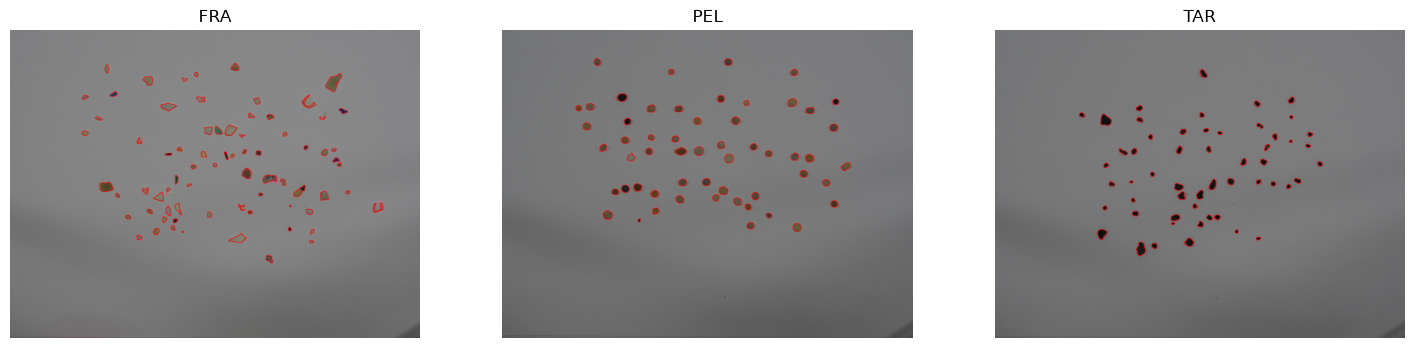

In [6]:
#Imágenes completas de entrenamiento (una clase por imagen) y la imagen de test
imagenes = {
    'FRA': 'fragment-03-olympus-10-01-2020.JPG',
    'PEL': 'pellet-03-olympus-10-01-2020.JPG',
    'TAR': 'tar-03-olympus-10-01-2020.JPG',
    'TEST': 'MPs_test.jpg'
}
clases = ['FRA', 'PEL', 'TAR']

contornos_img = {}       # contornos de cada imagen
caracteristicas = {}     # características de cada partícula de cada imagen
imgs = {}

for nombre, fichero in imagenes.items():
    img = cv2.imread(fichero)
    #Las imágenes de entrenamiento se reducen a la mitad para que las partículas
    #tengan un tamaño en píxeles parecido al de la imagen de test
    if nombre != 'TEST':
        img = cv2.resize(img, None, fx=0.5, fy=0.5)
    imgs[nombre] = img

    #Suavizado
    img_suave = cv2.GaussianBlur(img, (5, 5), 0)
    #Fondo estimado con un filtro de mediana grande (las partículas desaparecen)
    fondo = cv2.medianBlur(img_suave, 81)
    #Diferencia con el fondo (detecta partículas oscuras y claras), máximo de los 3 canales
    dif = cv2.absdiff(img_suave, fondo).max(axis=2)
    #Umbralizado fijo
    th, img_th = cv2.threshold(dif, 15, 255, cv2.THRESH_BINARY)

    #Obtiene únicamente los contornos externos
    contornos, hierarchy = cv2.findContours(img_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    alto, ancho = gris.shape

    contornos_img[nombre] = []
    caracteristicas[nombre] = []
    for c in contornos:
        #Área del contorno
        area = cv2.contourArea(c)
        #Área mínima
        if area < 40:
            continue
        #Contenedor alineado con ejes de la imagen
        x, y, w, h = cv2.boundingRect(c)
        #Se descartan contornos que tocan el borde (sombras, borde del papel)
        if x <= 2 or y <= 2 or x + w >= ancho - 2 or y + h >= alto - 2:
            continue

        #Perímetro y compacidad
        perimetro = cv2.arcLength(c, True)
        compacidad = perimetro ** 2 / area
        #Relación del área de la partícula con el área del contenedor
        rel_area = area / (w * h)
        #Relación del ancho y el alto del contenedor (mínimo contenedor ajustado)
        (cx, cy), (rw, rh), angulo = cv2.minAreaRect(c)
        rel_contenedor = min(rw, rh) / max(rw, rh)
        #Relación entre los ejes de la elipse ajustada
        if len(c) >= 5:
            (centro, ejes, orientacion) = cv2.fitEllipse(c)
            rel_elipse = min(ejes) / max(ejes)
        else:
            rel_elipse = 1.0
        #Relación entre las distancias menor y mayor del centroide al contorno
        M = cv2.moments(c)
        mx, my = M['m10'] / M['m00'], M['m01'] / M['m00']
        distancias = np.sqrt((c[:, 0, 0] - mx) ** 2 + (c[:, 0, 1] - my) ** 2)
        rel_dist = distancias.min() / distancias.max()

        #Apariencia: saturación media y brillo relativo al fondo dentro de la partícula
        mascara = np.zeros(gris.shape, np.uint8)
        cv2.drawContours(mascara, [c], -1, 255, -1)
        saturacion = cv2.mean(hsv, mascara)[1]
        brillo = cv2.mean(gris, mascara)[0] / np.median(gris)

        contornos_img[nombre].append(c)
        caracteristicas[nombre].append([compacidad, rel_area, rel_contenedor, rel_elipse,
                                        rel_dist, saturacion, brillo])

    print(nombre, 'partículas detectadas:', len(contornos_img[nombre]))

#Muestra los contornos de las imágenes de entrenamiento
plt.figure(figsize=(18, 5))
for i, clase in enumerate(clases):
    img_rgb = cv2.cvtColor(imgs[clase], cv2.COLOR_BGR2RGB)
    cv2.drawContours(img_rgb, contornos_img[clase], -1, (255, 0, 0), 2)
    plt.subplot(1, 3, i + 1)
    plt.axis("off")
    plt.imshow(img_rgb)
    plt.title(clase)
plt.show()

Acierto en entrenamiento: 0.8360655737704918
Partículas anotadas emparejadas: 106  No detectadas: 14


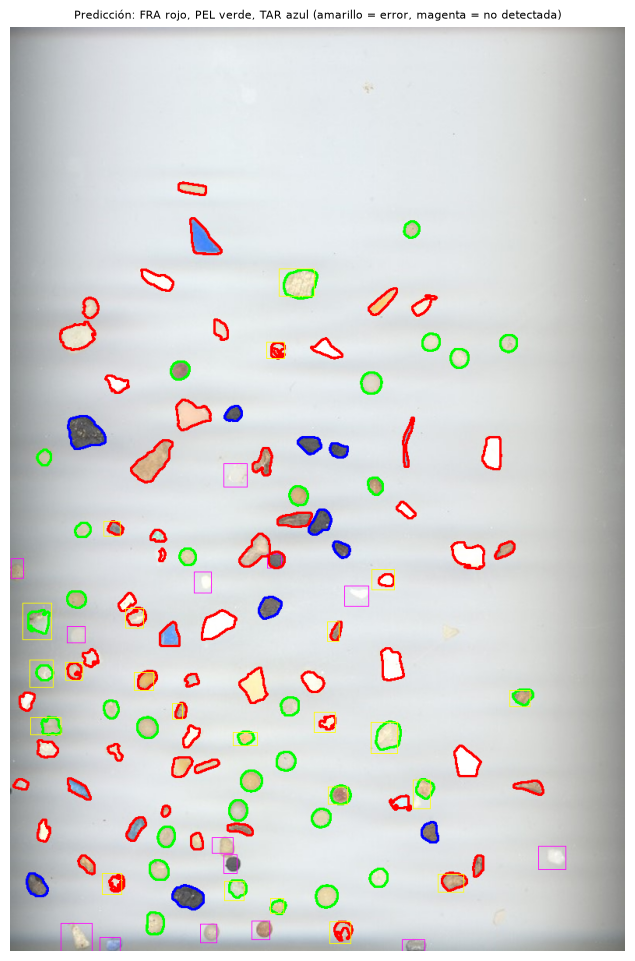

In [7]:
#Conjunto de entrenamiento: características y etiqueta de cada partícula
X = np.array(caracteristicas['FRA'] + caracteristicas['PEL'] + caracteristicas['TAR'])
y_train = ['FRA'] * len(caracteristicas['FRA']) + ['PEL'] * len(caracteristicas['PEL']) + ['TAR'] * len(caracteristicas['TAR'])

#Normalización (media 0 y desviación 1) con los datos de entrenamiento
media = X.mean(axis=0)
desv = X.std(axis=0)

#Centroide (vector medio normalizado) de cada clase
centroides = {}
for clase in clases:
    centroides[clase] = ((np.array(caracteristicas[clase]) - media) / desv).mean(axis=0)

#Clasificación del entrenamiento: clase del centroide más cercano
pred_train = []
for x in X:
    z = (x - media) / desv
    distancias = [np.linalg.norm(z - centroides[clase]) for clase in clases]
    pred_train.append(clases[np.argmin(distancias)])
print('Acierto en entrenamiento:', np.mean(np.array(pred_train) == np.array(y_train)))

#Contenedores de las partículas detectadas en la imagen de test
cajas_det = []
for c in contornos_img['TEST']:
    x, y, w, h = cv2.boundingRect(c)
    cajas_det.append([x, y, x + w, y + h])

# Colores de cada clase
colores = {
    "FRA": (0, 0, 255),   # Rojo
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

img = imgs['TEST'].copy()
y = []        # anotaciones
y_pred = []   # predicciones
no_detectadas = 0

# Carga csv y empareja cada anotación con la partícula detectada que más se solapa
with open("MPs_test_bbs.csv", newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        etiqueta = row["label"]
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])

        #Solape (intersección / unión) con cada contenedor detectado
        mejor_iou, mejor_j = 0, -1
        for j, (dx1, dy1, dx2, dy2) in enumerate(cajas_det):
            ancho_i = max(0, min(x_max, dx2) - max(x_min, dx1))
            alto_i = max(0, min(y_max, dy2) - max(y_min, dy1))
            interseccion = ancho_i * alto_i
            union = (x_max - x_min) * (y_max - y_min) + (dx2 - dx1) * (dy2 - dy1) - interseccion
            if interseccion / union > mejor_iou:
                mejor_iou, mejor_j = interseccion / union, j

        if mejor_iou > 0.4:
            #Clasifica la partícula con el centroide más cercano
            z = (np.array(caracteristicas['TEST'][mejor_j]) - media) / desv
            distancias = [np.linalg.norm(z - centroides[clase]) for clase in clases]
            prediccion = clases[np.argmin(distancias)]
            y.append(etiqueta)
            y_pred.append(prediccion)
            #Dibuja el contorno con el color de la clase predicha
            cv2.drawContours(img, [contornos_img['TEST'][mejor_j]], -1, colores[prediccion], 2)
            #Si la predicción es errónea, rectángulo amarillo
            if prediccion != etiqueta:
                cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (0, 255, 255), 1)
        else:
            no_detectadas += 1
            #Partícula anotada no detectada, rectángulo magenta
            cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (255, 0, 255), 1)

print('Partículas anotadas emparejadas:', len(y), ' No detectadas:', no_detectadas)

# Visualiza resultado
plt.figure(figsize=(8, 12))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Predicción: FRA rojo, PEL verde, TAR azul (amarillo = error, magenta = no detectada)", fontsize=8)
plt.axis('off')
plt.show()

Accuracy (TP/(n))= 0.7830188679245284
Precision (TP/(TP+FP)) = 0.789695550351288
Recall (TP/(TP+FN)) = 0.7830188679245284
F1 Score (2*(precision*recall)/(precision+recall)) = 0.7843382554006015


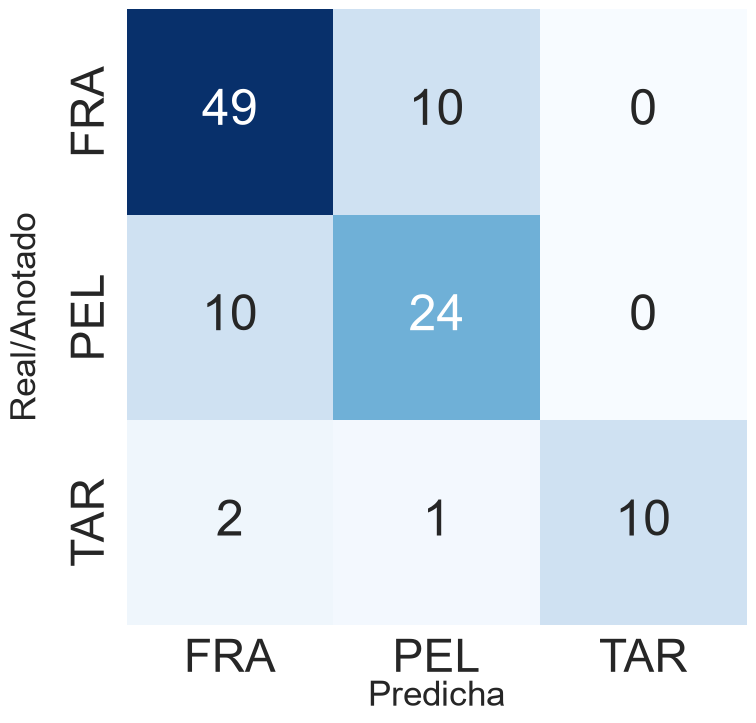

In [8]:
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

#Cálculo de métricas
accuracy = accuracy_score(y, y_pred)
#Para más de una clase se define la forma de promediar
precision = precision_score(y, y_pred,average='weighted')
recall = recall_score(y, y_pred,average='weighted')
f1score = f1_score(y, y_pred,average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")

conf_matrix = confusion_matrix(y, y_pred, labels=clases)
plt.figure(figsize=(8,8))
sns.set(font_scale = 3.0)

ax = sns.heatmap(
        conf_matrix, # confusion matrix 2D array
        annot=True, # Muestra números en las celdas
        fmt='d', # valores enteros
        cbar=False, # sin barra de colores
        cmap='Blues', # mapa de colores
        xticklabels=clases, # nombres de las clases
        yticklabels=clases
    )

#Etiquetas matriz de confusión
label_font = {'size':'25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)
plt.show()